# 4.0 - Operations Dashboard Data
**Week 4** | Turn predictions into tools a dispatcher can use: *which routes carry the highest predicted delay risk, filterable by region and carrier?*

Risk tiers (predicted delay vs SLA): **Low** < -0.5 h <= **Medium** < 1 h <= **High**.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
from src.modeling import predict as P, train as T
from src.run_pipeline import export_bi_tables
table = pd.read_csv(config.DATA_PROCESSED / 'shipments_enriched.csv', parse_dates=['dispatch_time','delivery_time'])
train, test, cut = T.chronological_split(table)
model = P.load_model(); scored = P.score_shipments(test, model)
print(scored.shape); scored.risk_tier.value_counts()

(6000, 47)


risk_tier
Low       4343
Medium    1169
High       488
Name: count, dtype: int64

## 1. Does the risk tier mean something?

In [2]:
chk = scored.groupby('risk_tier').agg(shipments=('shipment_id','size'), actual_late_rate=('is_late','mean'), avg_actual_delay=('hours_delayed','mean')).loc[['Low','Medium','High']]
chk.round(3)

,shipments,actual_late_rate,avg_actual_delay
risk_tier,,,
Low,4343,0.075,-2.131
Medium,1169,0.463,0.157
High,488,0.924,3.469


In [3]:
export_bi_tables(scored, table)
ops = pd.read_csv(config.DATA_PROCESSED / 'ops_dashboard_data.csv'); route = pd.read_csv(config.DATA_PROCESSED / 'route_risk_summary.csv')
print(ops.shape, route.shape)
ops.head(3)

(6000, 26) (70, 10)


,shipment_id,dispatch_time,dispatch_date,month_start,day_of_week,carrier_id,vehicle_type,origin_city,origin_region,dest_city,dest_region,route,distance_km,package_weight_kg,sla_hours,precip_mm,precip_flag,delivery_hours,hours_delayed,predicted_delay_h,predicted_delivery_h,residual_h,actual_late,predicted_late,risk_tier,carrier_name
0,115365,2025-08-24 07:32:00,2025-08-24,2025-08-01,Sunday,C06,van,Delhi,North,Hyderabad,South,Delhi -> Hyderabad,1268.34,10.48,76.0,0.0,0,74.06,-1.94,-0.75,75.25,-1.19,0,0,Low,EcoFreight
1,114842,2025-08-24 07:53:00,2025-08-24,2025-08-01,Sunday,C07,mini_truck,Hyderabad,South,Hyderabad,South,Hyderabad -> Hyderabad,7.48,109.86,6.0,0.0,0,4.93,-1.07,-1.37,4.63,0.30,0,0,Low,CityHop Couriers
2,117108,2025-08-24 07:55:00,2025-08-24,2025-08-01,Sunday,C07,van,Chennai,South,Indore,West,Chennai -> Indore,1183.86,6.20,72.0,0.0,0,65.65,-6.35,-4.52,67.48,-1.82,0,0,Low,CityHop Couriers


## 2. Highest-risk routes

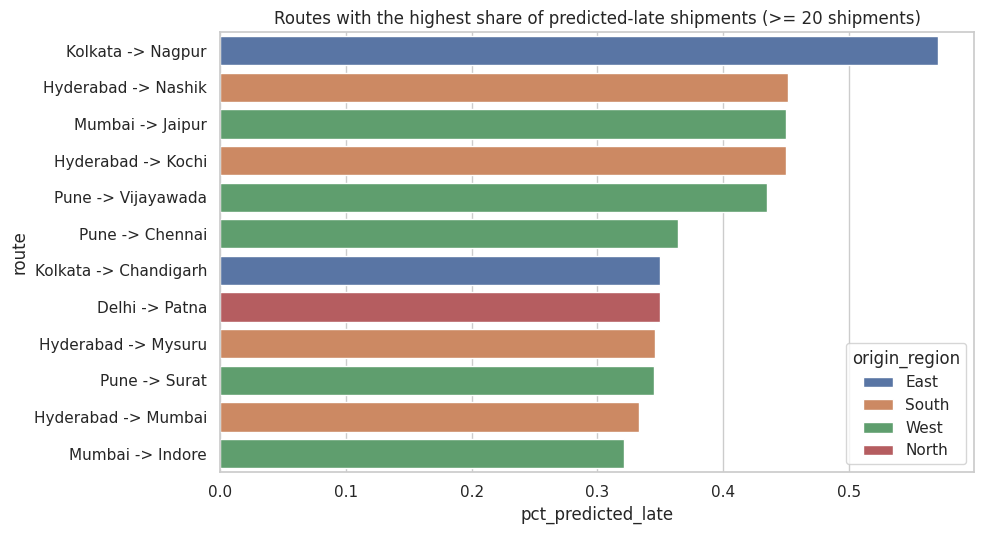

In [4]:
top = route.sort_values('pct_predicted_late', ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 5.5)); sns.barplot(data=top, y='route', x='pct_predicted_late', hue='origin_region', dodge=False, ax=ax); ax.set_title('Routes with the highest share of predicted-late shipments (>= 20 shipments)')
plt.tight_layout(); save('12_top_risk_routes.png'); plt.show()

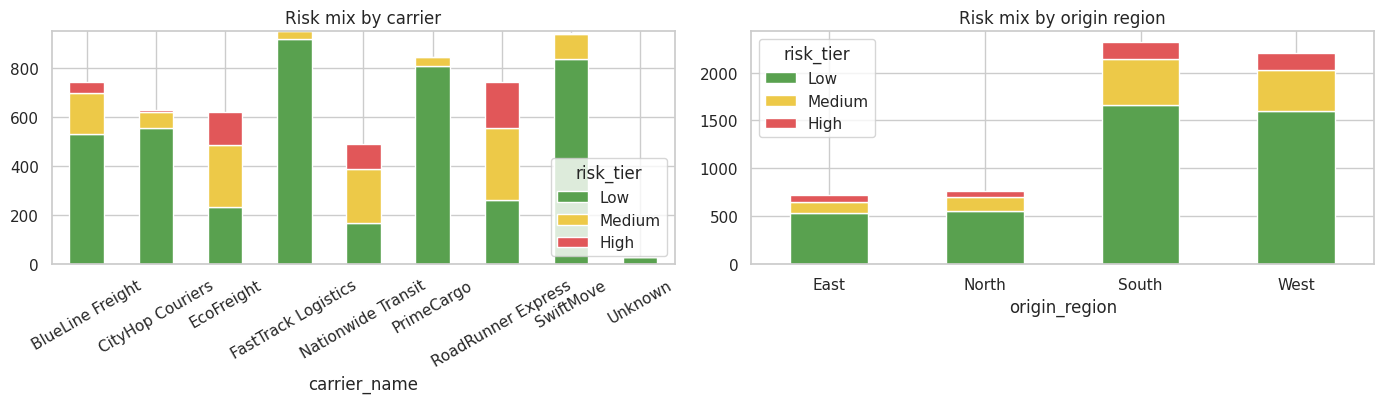

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ops.groupby(['carrier_name','risk_tier']).size().unstack().fillna(0)[['Low','Medium','High']].plot.bar(stacked=True, ax=ax[0], color=['#59a14f','#edc948','#e15759'], title='Risk mix by carrier'); ax[0].tick_params(axis='x', rotation=30)
ops.groupby(['origin_region','risk_tier']).size().unstack().fillna(0)[['Low','Medium','High']].plot.bar(stacked=True, ax=ax[1], color=['#59a14f','#edc948','#e15759'], title='Risk mix by origin region'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); save('13_risk_by_carrier_region.png'); plt.show()

## 3. Dispatcher worklist (High-risk, largest predicted delay first)

In [6]:
wl = ops[ops.risk_tier == 'High'].sort_values('predicted_delay_h', ascending=False)
wl[['shipment_id','dispatch_time','carrier_name','route','distance_km','sla_hours','predicted_delay_h','hours_delayed']].head(10)

,shipment_id,dispatch_time,carrier_name,route,distance_km,sla_hours,predicted_delay_h,hours_delayed
2734,121949,2025-10-27 06:02:00,Nationwide Transit,Kolkata -> Pune,1570.45,94.0,9.33,10.45
2446,102731,2025-10-20 20:19:00,RoadRunner Express,Delhi -> Kochi,2099.90,132.0,8.23,15.41
2913,129935,2025-10-29 19:07:00,Nationwide Transit,Kolkata -> Kochi,1908.86,116.0,7.97,3.73
1967,101243,2025-10-10 20:35:00,RoadRunner Express,Pune -> Kolkata,1577.60,96.0,7.92,12.18
4126,106165,2025-11-20 20:09:00,EcoFreight,Delhi -> Kochi,2081.32,130.0,7.71,8.37
2915,124639,2025-10-29 20:13:00,RoadRunner Express,Kolkata -> Pune,1582.00,96.0,7.12,8.87
4392,101687,2025-11-25 18:19:00,RoadRunner Express,Kolkata -> Pune,1570.89,96.0,6.98,11.53
3412,121708,2025-11-08 07:29:00,EcoFreight,Chennai -> Delhi,1751.14,98.0,6.65,9.06
208,122767,2025-08-28 23:44:00,Nationwide Transit,Chennai -> Chandigarh,1998.37,116.0,6.57,5.57
3062,116976,2025-11-01 18:02:00,RoadRunner Express,Bengaluru -> Ahmedabad,1245.05,74.0,6.39,10.35


## Files for Tableau / Power BI (`data/processed/`)
| File | Use |
|---|---|
| `ops_dashboard_data.csv` | **main table**: one row per test-set shipment with predictions, tier, carrier, region |
| `route_risk_summary.csv` | route-level risk ranking |
| `carrier_monthly_performance.csv` | carrier trend over time |

Build steps: `dashboard/TABLEAU_BUILD_GUIDE.md`. Interactive preview: `dashboard/ops_dashboard.html`.